# Two Way ANOVA
- Two-way ANOVA is a statistical method used to test the effects of two categorical variables on a continuous variable. It allows us to determine if there is a significant interaction between the two variables and if each variable has a significant main effect on the dependent variable.

In [1]:
import numpy as np
import pandas as pd
import statsmodels.api as sm
from statsmodels.formula.api import ols
import matplotlib.pyplot as plt
import seaborn as sns

In [4]:
# creating a data
df = pd.DataFrame({
    "water":np.repeat(["daily","weekly"],15),
    "sun": np.tile(np.repeat(["high","medium","low"],5),2),
    "height":[6,6,6,5,6,5,4,5,3,5
              ,4,3,7,8,9,4,3,2,6,5
              ,5,5,5,6,4,5,6,7,4,3]
})

In [5]:
df.head()

,water,sun,height
0,daily,high,6
1,daily,high,6
2,daily,high,6
3,daily,high,5
4,daily,high,6


Text(0.5, 1.0, 'Boxplot')

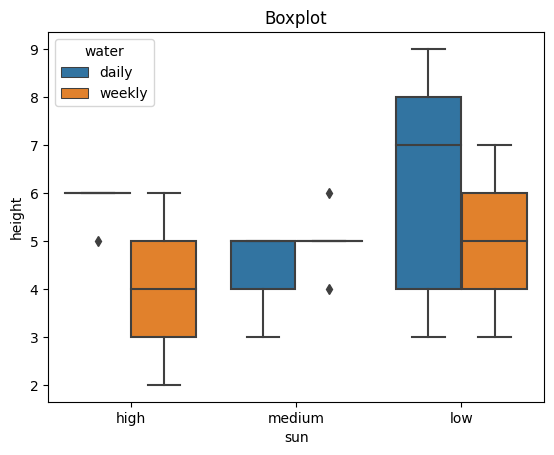

In [8]:
sns.boxplot(x="sun",y="height",data=df,hue="water")
plt.title("Boxplot")

- Two actors are being studied for height, we are studying sun and water impact on pant height. To study two factors we will use TWO WAY ANOVA

In [9]:
# fitting an ols model
# C(sun), individual effect of sun on plant height
# C(water), individual effect of water on plant height
#C(sun):C(water), combined effect of sun and water on plant height
model = ols('height ~ C(sun) + C(water) + C(sun):C(water) ',data=df).fit()

In [10]:
# calculating anova table using the model
anova_table = sm.stats.anova_lm(model,type=2)

In [11]:
anova_table

,df,sum_sq,mean_sq,F,PR(>F)
C(sun),2.0,4.466667,2.233333,1.015152,0.377385
C(water),1.0,4.800000,4.800000,2.181818,0.152652
C(sun):C(water),2.0,7.800000,3.900000,1.772727,0.191397
Residual,24.0,52.800000,2.200000,NaN,NaN


- No significant effect of sun on height, water on height and sun + water on height.

In [42]:
from statsmodels.stats.multicomp import pairwise_tukeyhsd

In [43]:
# Perform Tukey's HSD test
posthoc = pairwise_tukeyhsd(df['height'], df['sun'] + df['water'])
print(posthoc)


     Multiple Comparison of Means - Tukey HSD, FWER=0.05      
   group1      group2    meandiff p-adj   lower  upper  reject
--------------------------------------------------------------
  highdaily   highweekly     -1.8 0.4155 -4.7005 1.1005  False
  highdaily     lowdaily      0.4  0.998 -2.5005 3.3005  False
  highdaily    lowweekly     -0.8  0.954 -3.7005 2.1005  False
  highdaily  mediumdaily     -1.4 0.6721 -4.3005 1.5005  False
  highdaily mediumweekly     -0.8  0.954 -3.7005 2.1005  False
 highweekly     lowdaily      2.2 0.2154 -0.7005 5.1005  False
 highweekly    lowweekly      1.0 0.8899 -1.9005 3.9005  False
 highweekly  mediumdaily      0.4  0.998 -2.5005 3.3005  False
 highweekly mediumweekly      1.0 0.8899 -1.9005 3.9005  False
   lowdaily    lowweekly     -1.2 0.7931 -4.1005 1.7005  False
   lowdaily  mediumdaily     -1.8 0.4155 -4.7005 1.1005  False
   lowdaily mediumweekly     -1.2 0.7931 -4.1005 1.7005  False
  lowweekly  mediumdaily     -0.6 0.9867 -3.5005 2.3005

# Another way fro two way anova


In [13]:
# installing a library
!pip install pingouin

Looking in indexes: https://pypi.org/simple, https://us-python.pkg.dev/colab-wheels/public/simple/
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 198.6/198.6 KB 7.6 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done
  Created wheel for littleutils: filename=littleutils-0.2.2-py3-none-any.whl size=7048 sha256=c0a3778b0b2f4be27e434b397e319152e2635df1e19d01237e96ef86ff593399
  Stored in directory: /root/.cache/pip/wheels/04/bb/0d/2d02ec45f29c48d6192476bfb59c5a0e64b605e7212374dd15
Successfully built littleutils


In [14]:
import pingouin as pg

In [15]:
# dv, means numerical variable to study
# between, categorical variable among which to study the numerical variable
# detailed, to et detailed result
anova = pg.anova(df,dv="height",between=["water","sun"],detailed=True)

In [16]:
anova

,Source,SS,DF,MS,F,p-unc,np2
0,water,4.800000,1,4.800000,2.181818,0.152652,0.083333
1,sun,4.466667,2,2.233333,1.015152,0.377385,0.077998
2,water * sun,7.800000,2,3.900000,1.772727,0.191397,0.128713
3,Residual,52.800000,24,2.200000,NaN,NaN,NaN


In [62]:
posthoc = pg.pairwise_tests(data=df, dv='height', between=['sun', 'water'], 
                               padjust='holm',  parametric=True)

In [66]:
posthoc

,Contrast,sun,A,B,Paired,Parametric,T,dof,alternative,p-unc,p-corr,p-adjust,BF10,hedges
0,sun,-,high,low,False,True,-0.862367,18.0,two-sided,0.399830,0.799659,holm,0.516,-0.369367
1,sun,-,high,medium,False,True,0.379473,18.0,two-sided,0.708776,0.799659,holm,0.418,0.162535
2,sun,-,low,medium,False,True,1.252095,18.0,two-sided,0.226561,0.679683,holm,0.683,0.536294
3,water,-,daily,weekly,False,True,1.437210,28.0,two-sided,0.161740,NaN,NaN,0.745,0.510611
4,sun * water,high,daily,weekly,False,True,2.449490,8.0,two-sided,0.039969,0.119906,holm,2.132,1.399271
5,sun * water,low,daily,weekly,False,True,0.884652,8.0,two-sided,0.402149,0.546278,holm,0.624,0.505357
6,sun * water,medium,daily,weekly,False,True,-1.176697,8.0,two-sided,0.273139,0.546278,holm,0.74,-0.672188


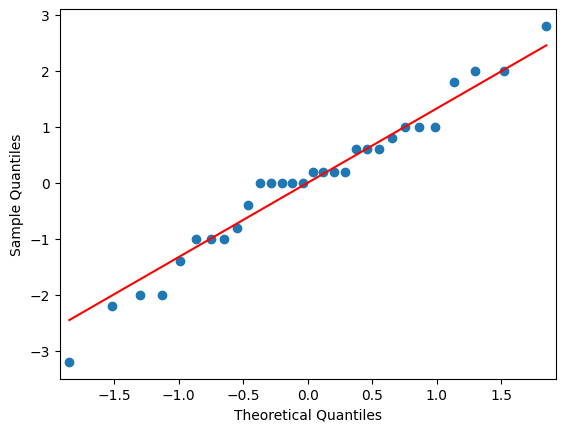

In [25]:
res = model.resid
fig = sm.qqplot(res,line="s")
plt.show()

In [38]:
penguin = sns.load_dataset("penguins")

In [40]:
penguin.head()

,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex
0,Adelie,Torgersen,39.1,18.7,181.0,3750.0,Male
1,Adelie,Torgersen,39.5,17.4,186.0,3800.0,Female
2,Adelie,Torgersen,40.3,18.0,195.0,3250.0,Female
3,Adelie,Torgersen,NaN,NaN,NaN,NaN,NaN
4,Adelie,Torgersen,36.7,19.3,193.0,3450.0,Female


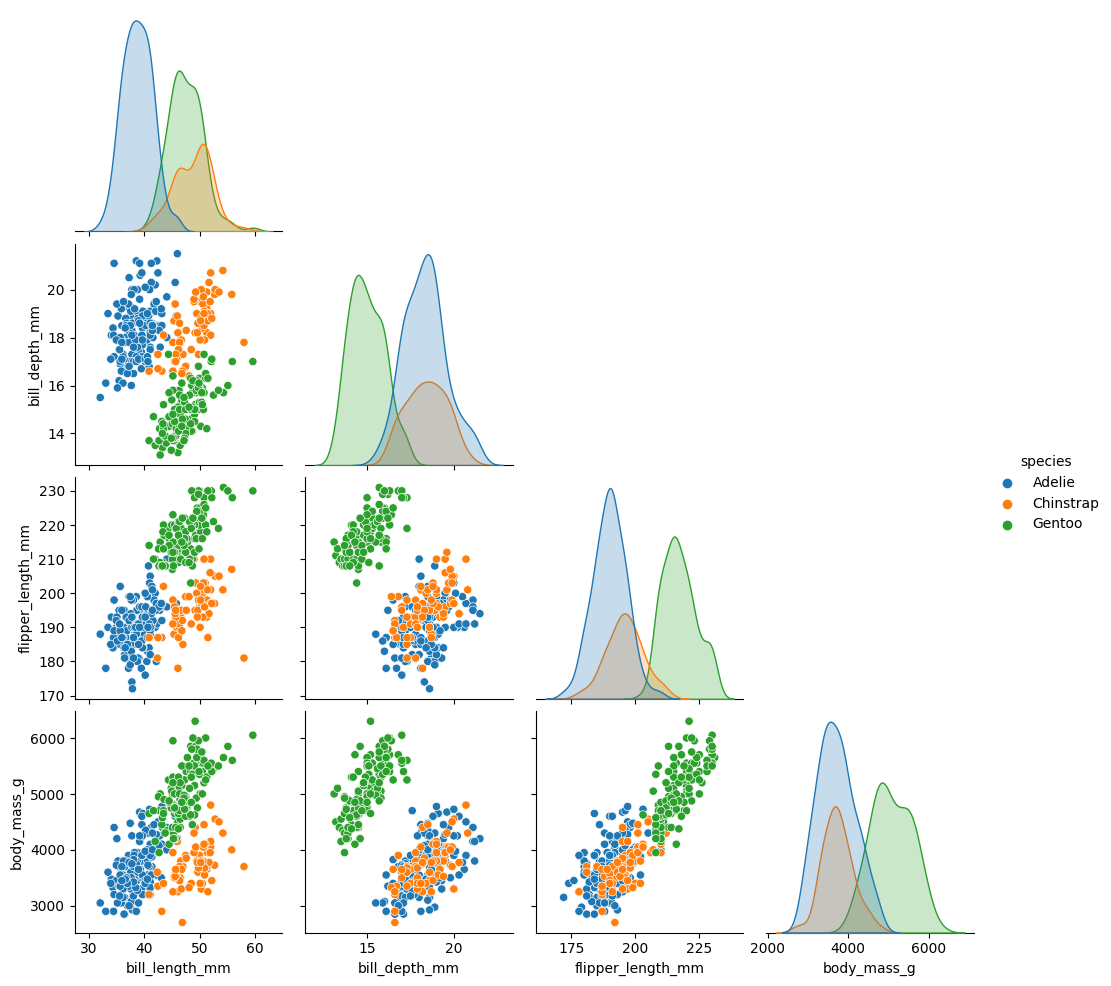

In [41]:
sns.pairplot(penguin,hue="species",corner=True,)